In [ ]:
# Import the required libraries
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt

# Date range  for the stock market data
start_date = "2021-01-01"
end_date = "2025-01-01"

# S&P 500 market index
market_index = "^GSPC"

print("Setup successfully completed")


Setup successfully completed


In [ ]:
# Install the library for downloading stock data
%pip install yfinance

In [ ]:

# Import the libraries
import requests
from io import StringIO

# Wikipedia page containing S&P 500 companies
url = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"

# Request the webpage
headers = {"User-Agent": "Mozilla/5.0"}
response = requests.get(url, headers=headers, timeout=30)

# Check whether the request was successful
response.raise_for_status()

# Read the company table
tables = pd.read_html(StringIO(response.text))
companies = tables[0]

# Display the first five rows
companies.head()


,Symbol,Security,GICS Sector,GICS Sub-Industry,Headquarters Location,Date added,CIK,Founded
0,MMM,3M,Industrials,Industrial Conglomerates,"Saint Paul, Minnesota",1957-03-04,66740,1902
1,AOS,A. O. Smith,Industrials,Building Products,"Milwaukee, Wisconsin",2017-07-26,91142,1916
2,ABT,Abbott Laboratories,Health Care,Health Care Equipment,"North Chicago, Illinois",1957-03-04,1800,1888
3,ABBV,AbbVie,Health Care,Biotechnology,"North Chicago, Illinois",2012-12-31,1551152,2013 (1888)
4,ACN,Accenture,Information Technology,IT Consulting & Other Services,"Dublin, Ireland",2011-07-06,1467373,1989


In [ ]:

# Get the stock symbols from the company table
stock_symbols = companies["Symbol"].tolist()

# Change dots to hyphens for Yahoo Finance
stock_symbols = [symbol.replace(".", "-") for symbol in stock_symbols]

# Check the number of symbols
print("Total stock symbols:", len(stock_symbols))

# Display the first 10 symbols
print("First 10 symbols:", stock_symbols[:10])


Total stock symbols: 503
First 10 symbols: ['MMM', 'AOS', 'ABT', 'ABBV', 'ACN', 'ADBE', 'AMD', 'AES', 'AFL', 'A']


In [ ]:

# Record when the company list was collected
from datetime import datetime, timezone

retrieval_date = datetime.now(timezone.utc).strftime("%Y-%m-%d")

print("Data retrieval date:", retrieval_date)

# Save the company information as a CSV file
companies.to_csv("sp500_companies.csv", index=False)

print("Company list saved successfully")


Data retrieval date: 2026-11-21
Company list saved successfully


In [ ]:

# Download Apple's historical stock data
apple_data = yf.download(
    "AAPL",
    start=start_date,
    end=end_date,
    auto_adjust=False,
    progress=False
)

# Display the first five rows
print("Number of trading days:", len(apple_data))

apple_data.head()


Number of trading days: 1005


Price,Adj Close,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,,
2021-01-04,125.537109,129.410004,133.610001,126.760002,133.520004,143301900
2021-01-05,127.089233,131.009995,131.740005,128.429993,128.889999,97664900
2021-01-06,122.811203,126.599998,131.050003,126.379997,127.720001,155088000
2021-01-07,127.001892,130.919998,131.630005,127.860001,128.360001,109578200
2021-01-08,128.098114,132.050003,132.630005,130.229996,132.429993,105158200


In [ ]:

# Add the market index to the stock list
all_symbols = stock_symbols + [market_index]

# Store the downloaded data
stock_data = {}

# Download 25 symbols at a time
batch_size = 25

for i in range(0, len(all_symbols), batch_size):

    batch = all_symbols[i:i + batch_size]

    print("Downloading batch:", i // batch_size + 1)

    data = yf.download(
        batch,
        start=start_date,
        end=end_date,
        auto_adjust=False,
        group_by="ticker",
        threads=True,
        progress=False
    )

    # Store each stock separately
    for symbol in batch:
        try:
            stock_data[symbol] = data[symbol].copy()
        except KeyError:
            print("No data returned for:", symbol)

print("Download process completed")
print("Number of datasets stored:", len(stock_data))


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['FDXF']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['HONA']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['Q']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['SNDK']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['VYLR']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Download process completed
Number of datasets stored: 504


In [ ]:

# Check which stocks have historical data
valid_symbols = []
failed_symbols = []

for symbol, data in stock_data.items():

    if data.empty or data["Close"].dropna().empty:
        failed_symbols.append(symbol)
    else:
        valid_symbols.append(symbol)

print("Stocks with data:", len(valid_symbols))
print("Stocks without data:", len(failed_symbols))
print("Symbols without data:", failed_symbols)

# Check the market index
print("Market index available:", market_index in valid_symbols)


Stocks with data: 499
Stocks without data: 5
Symbols without data: ['FDXF', 'HONA', 'Q', 'SNDK', 'VYLR']
Market index available: True


In [ ]:

# Save the downloaded stock data
import pickle

with open("sp500_raw_data.pkl", "wb") as file:
    pickle.dump(stock_data, file)

print("Historical stock data saved successfully")


Historical stock data saved successfully


In [ ]:

# Check for duplicate trading dates
duplicate_dates = {}

for symbol, data in stock_data.items():
    count = data.index.duplicated().sum()

    if count > 0:
        duplicate_dates[symbol] = count

print("Stocks with duplicate dates:", len(duplicate_dates))
print("Duplicate date details:", duplicate_dates)


Stocks with duplicate dates: 0
Duplicate date details: {}


In [ ]:

# Check missing values in the stock data
missing_values = {}

for symbol in valid_symbols:
    data = stock_data[symbol]

    missing_count = data[["Close", "Adj Close", "Volume"]].isna().sum().sum()

    if missing_count > 0:
        missing_values[symbol] = int(missing_count)

print("Datasets with missing values:", len(missing_values))
print("First 10 results:", list(missing_values.items())[:10])


Datasets with missing values: 10
First 10 results: [('APP', 210), ('COIN', 207), ('CEG', 789), ('EXE', 78), ('GEHC', 1476), ('GEV', 2436), ('RDDT', 2424), ('HOOD', 429), ('SOLV', 2433), ('VLTO', 2076)]


In [ ]:

# Check the available trading history for each stock
history_details = []

for symbol in valid_symbols:
    data = stock_data[symbol]

    # Keep dates with complete price and volume information
    complete_data = data.dropna(
        subset=["Close", "Adj Close", "Volume"]
    )

    if not complete_data.empty:
        history_details.append({
            "Symbol": symbol,
            "First Date": complete_data.index.min(),
            "Last Date": complete_data.index.max(),
            "Trading Days": len(complete_data)
        })

history_df = pd.DataFrame(history_details)

# Display stocks with the shortest histories
history_df.sort_values("Trading Days").head(15)


,Symbol,First Date,Last Date,Trading Days
210,GEV,2024-03-27,2024-12-31,193
411,SOLV,2024-03-26,2024-12-31,194
382,RDDT,2024-03-21,2024-12-31,197
462,VLTO,2023-10-04,2024-12-31,313
209,GEHC,2022-12-15,2024-12-31,513
123,CEG,2022-01-19,2024-12-31,742
390,HOOD,2021-07-29,2024-12-31,862
40,APP,2021-04-15,2024-12-31,935
116,COIN,2021-04-14,2024-12-31,936
181,EXE,2021-02-10,2024-12-31,979


In [ ]:

# Check invalid stock prices and trading volumes
invalid_data = []

for symbol in valid_symbols:
    data = stock_data[symbol]

    # Count invalid values
    invalid_close = (data["Close"] <= 0).sum()
    invalid_adj_close = (data["Adj Close"] <= 0).sum()
    negative_volume = (data["Volume"] < 0).sum()
    zero_volume = (data["Volume"] == 0).sum()

    invalid_data.append({
        "Symbol": symbol,
        "Invalid Close": int(invalid_close),
        "Invalid Adj Close": int(invalid_adj_close),
        "Negative Volume": int(negative_volume),
        "Zero Volume": int(zero_volume)
    })

invalid_df = pd.DataFrame(invalid_data)

# Show stocks with invalid values
problem_stocks = invalid_df[
    (invalid_df["Invalid Close"] > 0) |
    (invalid_df["Invalid Adj Close"] > 0) |
    (invalid_df["Negative Volume"] > 0) |
    (invalid_df["Zero Volume"] > 0)
]

print("Stocks with invalid values:", len(problem_stocks))

problem_stocks.head(20)


Stocks with invalid values: 3


,Symbol,Invalid Close,Invalid Adj Close,Negative Volume,Zero Volume
192,FERG,0,0,0,27
409,SW,0,0,0,424
498,^GSPC,0,0,0,1


In [ ]:

# Check dates with zero trading volume
for symbol in ["FERG", "SW", "^GSPC"]:
    data = stock_data[symbol]
    zero_days = data[data["Volume"] == 0]

    print("\nStock:", symbol)
    print("Zero-volume days:", len(zero_days))
    print("First date:", zero_days.index.min())
    print("Last date:", zero_days.index.max())



Stock: FERG
Zero-volume days: 27
First date: 2021-01-07 00:00:00
Last date: 2021-03-05 00:00:00

Stock: SW
Zero-volume days: 424
First date: 2021-01-05 00:00:00
Last date: 2024-07-05 00:00:00

Stock: ^GSPC
Zero-volume days: 1
First date: 2023-05-24 00:00:00
Last date: 2023-05-24 00:00:00


In [ ]:

# Check SW trading volume by year
sw_data = stock_data["SW"].copy()

sw_data["Year"] = sw_data.index.year

sw_volume_check = sw_data.groupby("Year")["Volume"].agg(
    Total_Days="count",
    Zero_Volume_Days=lambda x: (x == 0).sum(),
    Positive_Volume_Days=lambda x: (x > 0).sum()
)

print(sw_volume_check)


      Total_Days  Zero_Volume_Days  Positive_Volume_Days
Year                                                    
2021         252               130                   122
2022         251                96                   155
2023         250               121                   129
2024         252                77                   175


In [ ]:

# Check SW volume in the last 60 trading sessions
sw_last_60 = stock_data["SW"].tail(60)

zero_days = (sw_last_60["Volume"] == 0).sum()
positive_days = (sw_last_60["Volume"] > 0).sum()

print("Last 60 trading sessions:")
print("Zero-volume days:", int(zero_days))
print("Positive-volume days:", int(positive_days))
print("First date:", sw_last_60.index.min())
print("Last date:", sw_last_60.index.max())


Last 60 trading sessions:
Zero-volume days: 0
Positive-volume days: 60
First date: 2024-10-07 00:00:00
Last date: 2024-12-31 00:00:00


In [ ]:

# Check SW volume over the last 80 trading sessions
sw_last_80 = stock_data["SW"].tail(80)

print("Total sessions:", len(sw_last_80))
print("Zero-volume days:", int((sw_last_80["Volume"] == 0).sum()))
print("Positive-volume days:", int((sw_last_80["Volume"] > 0).sum()))
print("First date:", sw_last_80.index.min())
print("Last date:", sw_last_80.index.max())


Total sessions: 80
Zero-volume days: 0
Positive-volume days: 80
First date: 2024-09-09 00:00:00
Last date: 2024-12-31 00:00:00


In [ ]:

# Check zero volumes in the last 80 sessions for all stocks
recent_volume_problems = {}

for symbol in valid_symbols:

    if symbol == "^GSPC":
        continue

    data = stock_data[symbol].dropna(
        subset=["Close", "Adj Close", "Volume"]
    )

    if len(data) < 80:
        recent_volume_problems[symbol] = "Fewer than 80 sessions"
        continue

    last_80 = data.tail(80)

    zero_count = (last_80["Volume"] == 0).sum()

    if zero_count > 0:
        recent_volume_problems[symbol] = int(zero_count)

print("Stocks with recent volume problems:", len(recent_volume_problems))
print("Details:", recent_volume_problems)


Stocks with recent volume problems: 0
Details: {}


In [ ]:

# Check missing values within each stock's available history
internal_missing = {}

for symbol in valid_symbols:
    data = stock_data[symbol]

    complete = data[["Close", "Adj Close", "Volume"]].notna().all(axis=1)

    if complete.any():
        first_date = data.index[complete].min()
        last_date = data.index[complete].max()

        history = data.loc[first_date:last_date]

        missing_days = history[
            history[["Close", "Adj Close", "Volume"]].isna().any(axis=1)
        ]

        if len(missing_days) > 0:
            internal_missing[symbol] = len(missing_days)

print("Datasets with missing values inside their histories:",
      len(internal_missing))
print("Details:", internal_missing)


Datasets with missing values inside their histories: 0
Details: {}


In [ ]:

# Compare Close and Adj Close prices
adjustment_check = []

for symbol in valid_symbols:
    if symbol == "^GSPC":
        continue

    data = stock_data[symbol]

    difference = (data["Close"] - data["Adj Close"]).abs()

    adjustment_check.append({
        "Symbol": symbol,
        "Adjusted Days": int((difference > 0.01).sum())
    })

adjustment_df = pd.DataFrame(adjustment_check)

print("Stocks with adjusted price differences:",
      (adjustment_df["Adjusted Days"] > 0).sum())

adjustment_df.sort_values(
    "Adjusted Days", ascending=False
).head(10)


Stocks with adjusted price differences: 405


,Symbol,Adjusted Days
2,ABT,1005
497,ZTS,1005
0,MMM,1005
481,WEC,1005
479,WM,1005
478,DIS,1005
477,WMT,1005
476,WAB,1005
475,GWW,1005
474,WRB,1005


In [ ]:

# Check large changes in price adjustment factors
large_adjustments = []

for symbol in valid_symbols:
    if symbol == "^GSPC":
        continue

    data = stock_data[symbol].dropna(
        subset=["Close", "Adj Close"]
    ).sort_index()

    adjustment_factor = data["Adj Close"] / data["Close"]
    factor_change = adjustment_factor.pct_change().abs()

    large_days = factor_change[factor_change > 0.05]

    if len(large_days) > 0:
        large_adjustments.append({
            "Symbol": symbol,
            "Large Adjustment Days": len(large_days),
            "Maximum Change": factor_change.max()
        })

large_adjustments_df = pd.DataFrame(large_adjustments)

print("Stocks with large adjustment-factor changes:",
      len(large_adjustments_df))

large_adjustments_df.head(10)


Stocks with large adjustment-factor changes: 4


,Symbol,Large Adjustment Days,Maximum Change
0,ACGL,1,0.051637
1,F,1,0.063042
2,LYB,1,0.058699
3,TDG,1,0.055800


In [ ]:

# Find dates of large adjustment-factor changes
for symbol in ["ACGL", "F", "LYB", "TDG"]:

    data = stock_data[symbol].dropna(
        subset=["Close", "Adj Close"]
    ).sort_index()

    adjustment_factor = data["Adj Close"] / data["Close"]
    factor_change = adjustment_factor.pct_change()

    large_changes = factor_change[
        factor_change.abs() > 0.05
    ]

    print("\nStock:", symbol)
    print(large_changes)



Stock: ACGL
Date
2024-11-18    0.051637
dtype: float64

Stock: F
Date
2023-02-10    0.063042
dtype: float64

Stock: LYB
Date
2022-06-03    0.058699
dtype: float64

Stock: TDG
Date
2024-10-04    0.0558
dtype: float64


In [ ]:

# Check dividends and stock splits
for symbol in ["ACGL", "F", "LYB", "TDG"]:

    data = yf.Ticker(symbol).history(
        start=start_date,
        end=end_date,
        actions=True,
        auto_adjust=False
    )

    actions = data[
        (data["Dividends"] != 0) |
        (data["Stock Splits"] != 0)
    ]

    print("\nStock:", symbol)
    print(actions[["Dividends", "Stock Splits"]].tail(10))



Stock: ACGL
                           Dividends  Stock Splits
Date                                              
2024-11-18 00:00:00-05:00        5.0           0.0

Stock: F
                           Dividends  Stock Splits
Date                                              
2022-08-10 00:00:00-04:00       0.15           0.0
2022-11-14 00:00:00-05:00       0.15           0.0
2023-02-10 00:00:00-05:00       0.80           0.0
2023-04-25 00:00:00-04:00       0.15           0.0
2023-07-24 00:00:00-04:00       0.15           0.0
2023-10-31 00:00:00-04:00       0.15           0.0
2024-02-15 00:00:00-05:00       0.33           0.0
2024-05-07 00:00:00-04:00       0.15           0.0
2024-08-07 00:00:00-04:00       0.15           0.0
2024-11-07 00:00:00-05:00       0.15           0.0

Stock: LYB
                           Dividends  Stock Splits
Date                                              
2022-08-26 00:00:00-04:00       1.19           0.0
2022-11-25 00:00:00-05:00       1.19           

In [ ]:

# Check LYB corporate actions around 3 June 2022
lyb_data = yf.Ticker("LYB").history(
    start="2022-05-25",
    end="2022-06-11",
    actions=True,
    auto_adjust=False
)

print(lyb_data[["Close", "Dividends", "Stock Splits"]])


                                Close  Dividends  Stock Splits
Date                                                          
2022-05-25 00:00:00-04:00  109.010002       0.00           0.0
2022-05-26 00:00:00-04:00  111.500000       0.00           0.0
2022-05-27 00:00:00-04:00  117.080002       0.00           0.0
2022-05-31 00:00:00-04:00  114.250000       0.00           0.0
2022-06-01 00:00:00-04:00  114.309998       0.00           0.0
2022-06-02 00:00:00-04:00  115.250000       0.00           0.0
2022-06-03 00:00:00-04:00  107.400002       6.39           0.0
2022-06-06 00:00:00-04:00  109.830002       0.00           0.0
2022-06-07 00:00:00-04:00  112.300003       0.00           0.0
2022-06-08 00:00:00-04:00  109.980003       0.00           0.0
2022-06-09 00:00:00-04:00  108.220001       0.00           0.0
2022-06-10 00:00:00-04:00  102.570000       0.00           0.0


In [ ]:

# Convert daily adjusted prices into Friday-ending weekly prices
weekly_prices = {}

for symbol in valid_symbols:

    data = stock_data[symbol].sort_index()

    weekly = data["Adj Close"].resample("W-FRI").last()

    weekly_prices[symbol] = weekly

print("Weekly price datasets created:", len(weekly_prices))
print("\nApple weekly prices:")
print(weekly_prices["AAPL"].head(10))


Weekly price datasets created: 499

Apple weekly prices:
Date
2021-01-08    128.098099
2021-01-15    123.335045
2021-01-22    134.908020
2021-01-29    128.010818
2021-02-05    132.865387
2021-02-12    131.515015
2021-02-19    126.171638
2021-02-26    117.806808
2021-03-05    117.962250
2021-03-12    117.583336
Freq: W-FRI, Name: Adj Close, dtype: float64


In [ ]:

# Remove the incomplete final calendar week
for symbol in weekly_prices:

    weekly_prices[symbol] = weekly_prices[symbol][
        weekly_prices[symbol].index <= "2024-12-27"
    ]

print("Apple's last five weekly prices:")
print(weekly_prices["AAPL"].tail())

print("\nBenchmark's last five weekly prices:")
print(weekly_prices["^GSPC"].tail())


Apple's last five weekly prices:
Date
2024-11-29    235.441193
2024-12-06    240.907349
2024-12-13    246.155258
2024-12-20    252.464630
2024-12-27    253.555878
Freq: W-FRI, Name: Adj Close, dtype: float64

Benchmark's last five weekly prices:
Date
2024-11-29    6032.379883
2024-12-06    6090.270020
2024-12-13    6051.089844
2024-12-20    5930.850098
2024-12-27    5970.839844
Freq: W-FRI, Name: Adj Close, dtype: float64


In [ ]:

# Check missing weekly adjusted closing prices
missing_weeks = {}

for symbol, weekly in weekly_prices.items():

    missing_count = weekly.isna().sum()

    if missing_count > 0:
        missing_weeks[symbol] = int(missing_count)

print("Datasets with missing weekly prices:", len(missing_weeks))
print("First 15 results:", list(missing_weeks.items())[:15])


Datasets with missing weekly prices: 10
First 15 results: [('APP', 14), ('COIN', 14), ('CEG', 54), ('EXE', 5), ('GEHC', 101), ('GEV', 168), ('RDDT', 167), ('HOOD', 29), ('SOLV', 168), ('VLTO', 143)]


In [ ]:

# Check missing weeks within available trading histories
internal_weekly_gaps = {}

for symbol, weekly in weekly_prices.items():

    first_week = weekly.first_valid_index()
    last_week = weekly.last_valid_index()

    if first_week is not None:
        active_weeks = weekly.loc[first_week:last_week]

        missing_count = active_weeks.isna().sum()

        if missing_count > 0:
            internal_weekly_gaps[symbol] = int(missing_count)

print("Datasets with internal missing weeks:",
      len(internal_weekly_gaps))

print("Details:", internal_weekly_gaps)


Datasets with internal missing weeks: 0
Details: {}


In [ ]:

# Calculate weekly returns using adjusted closing prices
weekly_returns = {}

for symbol, weekly in weekly_prices.items():

    # Calculate returns without filling missing prices
    returns = weekly.pct_change(fill_method=None)

    # Remove missing returns
    weekly_returns[symbol] = returns.dropna()

print("Weekly return datasets created:", len(weekly_returns))

print("\nApple weekly returns:")
print(weekly_returns["AAPL"].head(10))


Weekly return datasets created: 499

Apple weekly returns:
Date
2021-01-15   -0.037183
2021-01-22    0.093834
2021-01-29   -0.051125
2021-02-05    0.037923
2021-02-12   -0.010163
2021-02-19   -0.040629
2021-02-26   -0.066297
2021-03-05    0.001319
2021-03-12   -0.003212
2021-03-19   -0.008593
Freq: W-FRI, Name: Adj Close, dtype: float64


In [ ]:

# Calculate mean weekly returns for each stock
mean_weekly_returns = {}

for symbol, returns in weekly_returns.items():

    if symbol == "^GSPC":
        continue

    mean_weekly_returns[symbol] = returns.mean()

mean_returns_df = pd.DataFrame(
    list(mean_weekly_returns.items()),
    columns=["Symbol", "Mean Weekly Return"]
)

print("Stocks with mean weekly returns:", len(mean_returns_df))

print("\nFirst 10 stocks:")
print(mean_returns_df.head(10))


Stocks with mean weekly returns: 498

First 10 stocks:
  Symbol  Mean Weekly Return
0    MMM            0.001142
1    AOS            0.001991
2    ABT            0.000971
3   ABBV            0.003749
4    ACN            0.002376
5   ADBE            0.000990
6    AMD            0.003624
7    AES           -0.001420
8    AFL            0.005004
9      A            0.001121


In [ ]:

# Calculate weekly beta for each stock
market_returns = weekly_returns["^GSPC"]

beta_results = []

for symbol, stock_returns in weekly_returns.items():

    if symbol == "^GSPC":
        continue

    # Align stock and market returns using matching weeks
    aligned = pd.concat(
        [stock_returns, market_returns],
        axis=1,
        join="inner"
    ).dropna()

    aligned.columns = ["Stock Return", "Market Return"]

    # Count the matching weekly observations
    weeks = len(aligned)

    if weeks >= 2:
        covariance = aligned["Stock Return"].cov(
            aligned["Market Return"]
        )

        market_variance = aligned["Market Return"].var()

        if market_variance > 0:
            beta = covariance / market_variance
        else:
            beta = np.nan
    else:
        beta = np.nan

    beta_results.append({
        "Symbol": symbol,
        "Weekly Beta": beta,
        "Weeks Used": weeks
    })

beta_df = pd.DataFrame(beta_results)

print("Stocks with beta results:", len(beta_df))
print("\nFirst 10 results:")
print(beta_df.head(10))


Stocks with beta results: 498

First 10 results:
  Symbol  Weekly Beta  Weeks Used
0    MMM     0.869079         207
1    AOS     1.042806         207
2    ABT     0.583543         207
3   ABBV     0.425365         207
4    ACN     1.143300         207
5   ADBE     1.553525         207
6    AMD     1.877622         207
7    AES     1.143911         207
8    AFL     0.707197         207
9      A     1.074723         207


In [ ]:

# Combine mean weekly returns and weekly beta
stock_features = pd.merge(
    mean_returns_df,
    beta_df,
    on="Symbol",
    how="inner"
)

print("Total stocks in feature table:", len(stock_features))

print("\nFirst 10 stocks:")
print(stock_features.head(10))

print("\nMissing values:")
print(stock_features.isna().sum())


Total stocks in feature table: 498

First 10 stocks:
  Symbol  Mean Weekly Return  Weekly Beta  Weeks Used
0    MMM            0.001142     0.869079         207
1    AOS            0.001991     1.042806         207
2    ABT            0.000971     0.583543         207
3   ABBV            0.003749     0.425365         207
4    ACN            0.002376     1.143300         207
5   ADBE            0.000990     1.553525         207
6    AMD            0.003624     1.877622         207
7    AES           -0.001420     1.143911         207
8    AFL            0.005004     0.707197         207
9      A            0.001121     1.074723         207

Missing values:
Symbol                0
Mean Weekly Return    0
Weekly Beta           0
Weeks Used            0
dtype: int64


In [ ]:

# Check weekly observation counts
print("Minimum weeks:", stock_features["Weeks Used"].min())
print("Maximum weeks:", stock_features["Weeks Used"].max())

print("\nStocks with the fewest weekly observations:")
print(
    stock_features.sort_values("Weeks Used").head(15)
)


Minimum weeks: 39
Maximum weeks: 207

Stocks with the fewest weekly observations:
    Symbol  Mean Weekly Return  Weekly Beta  Weeks Used
411   SOLV           -0.000197     0.108047          39
210    GEV            0.024936     1.338606          39
382   RDDT            0.038491     2.486226          40
462   VLTO            0.004906     0.786094          64
209   GEHC            0.003880     0.934954         106
123    CEG            0.012711     1.095554         153
390   HOOD            0.004963     1.833168         178
116   COIN            0.006697     3.004326         193
40     APP            0.014393     2.434869         193
181    EXE            0.006216     0.843292         202
495   ZBRA            0.001181     1.618418         207
494    YUM            0.001807     0.631435         207
493    XYL            0.001358     1.138381         207
492    XEL            0.001174     0.369321         207
491   WYNN            0.000740     0.998868         207


In [ ]:

# Compare minimum weekly observation thresholds
for minimum_weeks in [26, 52, 104, 156]:

    included = (
        stock_features["Weeks Used"] >= minimum_weeks
    ).sum()

    excluded = (
        stock_features["Weeks Used"] < minimum_weeks
    ).sum()

    print(
        "Minimum weeks:", minimum_weeks,
        "| Included:", included,
        "| Excluded:", excluded
    )


Minimum weeks: 26 | Included: 498 | Excluded: 0
Minimum weeks: 52 | Included: 495 | Excluded: 3
Minimum weeks: 104 | Included: 494 | Excluded: 4
Minimum weeks: 156 | Included: 492 | Excluded: 6


In [ ]:

# Identify stocks with fewer than 52 weekly observations
short_history_stocks = stock_features[
    stock_features["Weeks Used"] < 52
]

print("Stocks below 52 weeks:", len(short_history_stocks))

print(short_history_stocks[
    ["Symbol", "Weeks Used"]
])


Stocks below 52 weeks: 3
    Symbol  Weeks Used
210    GEV          39
382   RDDT          40
411   SOLV          39


In [ ]:

# Find the common RFM observation date
observation_date = stock_data["^GSPC"].index.max()

print("RFM observation date:", observation_date)

# Check the latest available date for each stock
latest_dates = {}

for symbol in valid_symbols:
    if symbol == "^GSPC":
        continue

    data = stock_data[symbol].dropna(
        subset=["Close", "Volume"]
    )

    latest_dates[symbol] = data.index.max()

print("Stocks ending on observation date:",
      sum(date == observation_date for date in latest_dates.values()))

print("Stocks ending earlier:",
      sum(date < observation_date for date in latest_dates.values()))


RFM observation date: 2024-12-31 00:00:00
Stocks ending on observation date: 498
Stocks ending earlier: 0


In [ ]:

# Identify high-volume trading days for Apple
apple = stock_data["AAPL"].copy()

# Average volume of the previous 20 trading sessions
apple["Previous 20 Day Average"] = (
    apple["Volume"]
    .shift(1)
    .rolling(window=20, min_periods=20)
    .mean()
)

# Identify unusually high-volume events
apple["High Volume Event"] = (
    apple["Volume"] > 2 * apple["Previous 20 Day Average"]
)

print("Apple high-volume events:",
      apple["High Volume Event"].sum())

print("\nFirst 5 high-volume events:")
print(
    apple.loc[
        apple["High Volume Event"],
        ["Volume", "Previous 20 Day Average"]
    ].head()
)


Apple high-volume events: 19

First 5 high-volume events:
Price          Volume  Previous 20 Day Average
Date                                          
2021-11-18  137827700               66310530.0
2021-11-30  174048100               75849045.0
2022-09-16  162278800               77520305.0
2022-12-16  160156900               72370250.0
2023-02-03  154357300               71921200.0


In [ ]:

# Calculate high-volume events for all stocks
volume_events = {}

for symbol in valid_symbols:

    if symbol == "^GSPC":
        continue

    data = stock_data[symbol].copy()

    # Calculate the previous 20 trading days' average volume
    data["Previous 20 Day Average"] = (
        data["Volume"]
        .shift(1)
        .rolling(window=20, min_periods=20)
        .mean()
    )

    # Identify high-volume events
    data["High Volume Event"] = (
        data["Volume"] > 2 * data["Previous 20 Day Average"]
    )

    volume_events[symbol] = data

print("Stocks processed:", len(volume_events))

print("Apple high-volume events:",
      volume_events["AAPL"]["High Volume Event"].sum())

print("Stocks with no high-volume events:",
      sum(
          data["High Volume Event"].sum() == 0
          for data in volume_events.values()
      ))


Stocks processed: 498
Apple high-volume events: 19
Stocks with no high-volume events: 0


In [ ]:

# Calculate Recency for each stock
recency_results = []

for symbol, data in volume_events.items():

    # Find dates with high-volume events
    event_dates = data.index[data["High Volume Event"]]

    if len(event_dates) > 0:
        last_event_date = event_dates.max()

        # Calculate calendar days since the last event
        recency = (observation_date - last_event_date).days

    else:
        last_event_date = pd.NaT
        recency = np.nan

    recency_results.append({
        "Symbol": symbol,
        "Last High Volume Event": last_event_date,
        "Recency": recency
    })

recency_df = pd.DataFrame(recency_results)

print("Stocks with Recency results:", len(recency_df))

print("\nFirst 10 results:")
print(recency_df.head(10))

print("\nMissing Recency values:")
print(recency_df["Recency"].isna().sum())


Stocks with Recency results: 498

First 10 results:
  Symbol Last High Volume Event  Recency
0    MMM             2024-12-20       11
1    AOS             2024-12-20       11
2    ABT             2024-12-20       11
3   ABBV             2024-12-20       11
4    ACN             2024-12-20       11
5   ADBE             2024-12-13       18
6    AMD             2024-12-13       18
7    AES             2024-11-07       54
8    AFL             2024-12-20       11
9      A             2024-12-20       11

Missing Recency values:
0


In [ ]:

# Calculate Frequency for each stock
frequency_results = []

for symbol, data in volume_events.items():

    # Use the final 60 trading sessions
    last_60_days = data.loc[
        data.index <= observation_date
    ].tail(60)

    # Count high-volume events
    frequency = last_60_days["High Volume Event"].sum()

    frequency_results.append({
        "Symbol": symbol,
        "Frequency": int(frequency)
    })

frequency_df = pd.DataFrame(frequency_results)

print("Stocks with Frequency results:", len(frequency_df))

print("\nFirst 10 results:")
print(frequency_df.head(10))

print("\nMinimum Frequency:", frequency_df["Frequency"].min())
print("Maximum Frequency:", frequency_df["Frequency"].max())


Stocks with Frequency results: 498

First 10 results:
  Symbol  Frequency
0    MMM          4
1    AOS          2
2    ABT          1
3   ABBV          3
4    ACN          2
5   ADBE          3
6    AMD          4
7    AES          3
8    AFL          2
9      A          2

Minimum Frequency: 0
Maximum Frequency: 8


In [ ]:

# Calculate Monetary for each stock
monetary_results = []

for symbol, data in volume_events.items():

    # Select the final 60 trading sessions
    last_60_days = data.loc[
        data.index <= observation_date
    ].tail(60)

    # Calculate daily traded value
    daily_value = (
        last_60_days["Close"] * last_60_days["Volume"]
    )

    # Calculate total traded value
    monetary = daily_value.sum()

    monetary_results.append({
        "Symbol": symbol,
        "Monetary": monetary
    })

monetary_df = pd.DataFrame(monetary_results)

print("Stocks with Monetary results:", len(monetary_df))

print("\nFirst 10 results:")
print(monetary_df.head(10))

print("\nMissing Monetary values:")
print(monetary_df["Monetary"].isna().sum())


Stocks with Monetary results: 498

First 10 results:
  Symbol      Monetary
0    MMM  2.599146e+10
1    AOS  4.748980e+09
2    ABT  3.523027e+10
3   ABBV  6.837054e+10
4    ACN  5.199430e+10
5   ADBE  1.030403e+11
6    AMD  3.131659e+11
7    AES  1.119578e+10
8    AFL  1.328456e+10
9      A  1.400180e+10

Missing Monetary values:
0


In [ ]:

# Combine Recency, Frequency and Monetary
rfm_df = pd.merge(
    recency_df,
    frequency_df,
    on="Symbol",
    how="inner"
)

rfm_df = pd.merge(
    rfm_df,
    monetary_df,
    on="Symbol",
    how="inner"
)

print("Total stocks in RFM dataset:", len(rfm_df))

print("\nFirst 10 stocks:")
print(rfm_df.head(10))

print("\nMissing values:")
print(rfm_df.isna().sum())


Total stocks in RFM dataset: 498

First 10 stocks:
  Symbol Last High Volume Event  Recency  Frequency      Monetary
0    MMM             2024-12-20       11          4  2.599146e+10
1    AOS             2024-12-20       11          2  4.748980e+09
2    ABT             2024-12-20       11          1  3.523027e+10
3   ABBV             2024-12-20       11          3  6.837054e+10
4    ACN             2024-12-20       11          2  5.199430e+10
5   ADBE             2024-12-13       18          3  1.030403e+11
6    AMD             2024-12-13       18          4  3.131659e+11
7    AES             2024-11-07       54          3  1.119578e+10
8    AFL             2024-12-20       11          2  1.328456e+10
9      A             2024-12-20       11          2  1.400180e+10

Missing values:
Symbol                    0
Last High Volume Event    0
Recency                   0
Frequency                 0
Monetary                  0
dtype: int64


In [ ]:

# Validate the final 60 trading sessions
validation_results = []

for symbol, data in volume_events.items():

    last_60 = data.loc[
        data.index <= observation_date
    ].tail(60)

    validation_results.append({
        "Symbol": symbol,
        "Trading Days": len(last_60),
        "Missing Close": last_60["Close"].isna().sum(),
        "Missing Volume": last_60["Volume"].isna().sum(),
        "Zero Volume": (last_60["Volume"] == 0).sum()
    })

validation_df = pd.DataFrame(validation_results)

print("Stocks checked:", len(validation_df))

print("\nStocks with validation issues:")
print(
    validation_df[
        (validation_df["Trading Days"] < 60) |
        (validation_df["Missing Close"] > 0) |
        (validation_df["Missing Volume"] > 0) |
        (validation_df["Zero Volume"] > 0)
    ]
)

print("\nTotal stocks with 60 trading days:",
      (validation_df["Trading Days"] == 60).sum())


Stocks checked: 498

Stocks with validation issues:
Empty DataFrame
Columns: [Symbol, Trading Days, Missing Close, Missing Volume, Zero Volume]
Index: []

Total stocks with 60 trading days: 498


In [ ]:

# Select stocks with at least 52 weekly observations
eligible_stocks = stock_features[
    stock_features["Weeks Used"] >= 52
].copy()

# Combine return, beta and RFM features
final_features = pd.merge(
    eligible_stocks,
    rfm_df,
    on="Symbol",
    how="inner"
)

print("Stocks in final feature dataset:", len(final_features))

print("\nFirst 10 stocks:")
print(final_features.head(10))

print("\nMissing values:")
print(final_features.isna().sum())


Stocks in final feature dataset: 495

First 10 stocks:
  Symbol  Mean Weekly Return  Weekly Beta  Weeks Used Last High Volume Event  \
0    MMM            0.001142     0.869079         207             2024-12-20   
1    AOS            0.001991     1.042806         207             2024-12-20   
2    ABT            0.000971     0.583543         207             2024-12-20   
3   ABBV            0.003749     0.425365         207             2024-12-20   
4    ACN            0.002376     1.143300         207             2024-12-20   
5   ADBE            0.000990     1.553525         207             2024-12-13   
6    AMD            0.003624     1.877622         207             2024-12-13   
7    AES           -0.001420     1.143911         207             2024-11-07   
8    AFL            0.005004     0.707197         207             2024-12-20   
9      A            0.001121     1.074723         207             2024-12-20   

   Recency  Frequency      Monetary  
0       11          4  2.5

In [ ]:

# Select the five features for analysis
feature_columns = [
    "Mean Weekly Return",
    "Weekly Beta",
    "Recency",
    "Frequency",
    "Monetary"
]

# Calculate descriptive statistics
feature_summary = final_features[feature_columns].describe()

print("Descriptive statistics:")
print(feature_summary.round(4))


Descriptive statistics:
       Mean Weekly Return  Weekly Beta   Recency  Frequency      Monetary
count            495.0000     495.0000  495.0000   495.0000  4.950000e+02
mean               0.0029       0.9822   20.5273     3.0000  3.963442e+10
std                0.0027       0.4209   21.3077     1.3286  1.282609e+11
min               -0.0045       0.0555    4.0000     0.0000  1.297483e+09
25%                0.0012       0.6718   11.0000     2.0000  1.025172e+10
50%                0.0027       0.9532   11.0000     3.0000  1.670905e+10
75%                0.0043       1.1806   18.0000     4.0000  3.257858e+10
max                0.0178       3.7786  222.0000     8.0000  1.847697e+12


In [ ]:

# Check the skewness of the five features
skewness = final_features[feature_columns].skew()

print("Feature skewness:")
print(skewness.round(3))

# Compare Monetary before and after log transformation
final_features["Log Monetary"] = np.log1p(
    final_features["Monetary"]
)

print("\nMonetary skewness before log:",
      round(final_features["Monetary"].skew(), 3))

print("Monetary skewness after log:",
      round(final_features["Log Monetary"].skew(), 3))


Feature skewness:
Mean Weekly Return     0.969
Weekly Beta            1.252
Recency                3.599
Frequency              0.411
Monetary              11.707
dtype: float64

Monetary skewness before log: 11.707
Monetary skewness after log: 1.07


In [ ]:

# Prepare the Return-Beta feature set
return_beta_features = final_features[
    ["Mean Weekly Return", "Weekly Beta"]
].copy()

# Prepare the RFM feature set
rfm_features = final_features[
    ["Recency", "Frequency", "Log Monetary"]
].copy()

print("Return-Beta dataset shape:",
      return_beta_features.shape)

print("RFM dataset shape:",
      rfm_features.shape)

print("\nReturn-Beta features:")
print(return_beta_features.head())

print("\nRFM features:")
print(rfm_features.head())


Return-Beta dataset shape: (495, 2)
RFM dataset shape: (495, 3)

Return-Beta features:
   Mean Weekly Return  Weekly Beta
0            0.001142     0.869079
1            0.001991     1.042806
2            0.000971     0.583543
3            0.003749     0.425365
4            0.002376     1.143300

RFM features:
   Recency  Frequency  Log Monetary
0       11          4     23.981034
1       11          2     22.281196
2       11          1     24.285172
3       11          3     24.948208
4       11          2     24.674400


In [ ]:

# Import StandardScaler
from sklearn.preprocessing import StandardScaler

# Standardise Return-Beta features
return_beta_scaler = StandardScaler()

return_beta_scaled = return_beta_scaler.fit_transform(
    return_beta_features
)

# Standardise RFM features separately
rfm_scaler = StandardScaler()

rfm_scaled = rfm_scaler.fit_transform(
    rfm_features
)

print("Return-Beta scaled shape:", return_beta_scaled.shape)
print("RFM scaled shape:", rfm_scaled.shape)

print("\nReturn-Beta means:")
print(return_beta_scaled.mean(axis=0).round(4))

print("\nRFM means:")
print(rfm_scaled.mean(axis=0).round(4))

print("\nReturn-Beta standard deviations:")
print(return_beta_scaled.std(axis=0).round(4))

print("\nRFM standard deviations:")
print(rfm_scaled.std(axis=0).round(4))


Return-Beta scaled shape: (495, 2)
RFM scaled shape: (495, 3)

Return-Beta means:
[0. 0.]

RFM means:
[-0. -0.  0.]

Return-Beta standard deviations:
[1. 1.]

RFM standard deviations:
[1. 1. 1.]


In [ ]:

# Import clustering tools
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Test different numbers of clusters
return_beta_results = []

for k in range(2, 9):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(return_beta_scaled)

    score = silhouette_score(
        return_beta_scaled,
        labels
    )

    return_beta_results.append({
        "Clusters": k,
        "Silhouette Score": score,
        "Inertia": model.inertia_
    })

# Create a results table
return_beta_scores = pd.DataFrame(return_beta_results)

print("Return-Beta K-means results:")
print(return_beta_scores.round(4))


Return-Beta K-means results:
   Clusters  Silhouette Score   Inertia
0         2            0.3903  631.0920
1         3            0.3186  477.8213
2         4            0.3232  376.8396
3         5            0.3370  316.4997
4         6            0.3376  262.8670
5         7            0.3289  228.3176
6         8            0.3525  194.8588


In [ ]:

# Compare cluster sizes for K = 2 and K = 8

for k in [2, 8]:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(return_beta_scaled)

    cluster_sizes = pd.Series(labels).value_counts().sort_index()

    print("\nNumber of clusters:", k)
    print("Cluster sizes:")
    print(cluster_sizes)

    print("Smallest cluster:", cluster_sizes.min())
    print("Largest cluster:", cluster_sizes.max())



Number of clusters: 2
Cluster sizes:
0    349
1    146
Name: count, dtype: int64
Smallest cluster: 146
Largest cluster: 349

Number of clusters: 8
Cluster sizes:
0    138
1     40
2     77
3     80
4      7
5     30
6     79
7     44
Name: count, dtype: int64
Smallest cluster: 7
Largest cluster: 138


In [ ]:

# Apply K-means with 2 clusters
return_beta_kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

# Assign clusters
return_beta_labels = return_beta_kmeans.fit_predict(
    return_beta_scaled
)

# Store cluster labels
final_features["Return-Beta KMeans Cluster"] = return_beta_labels

print("First 10 stock assignments:")
print(
    final_features[
        ["Symbol", "Mean Weekly Return",
         "Weekly Beta", "Return-Beta KMeans Cluster"]
    ].head(10)
)

print("\nCluster sizes:")
print(
    final_features[
        "Return-Beta KMeans Cluster"
    ].value_counts().sort_index()
)


First 10 stock assignments:
  Symbol  Mean Weekly Return  Weekly Beta  Return-Beta KMeans Cluster
0    MMM            0.001142     0.869079                           0
1    AOS            0.001991     1.042806                           0
2    ABT            0.000971     0.583543                           0
3   ABBV            0.003749     0.425365                           0
4    ACN            0.002376     1.143300                           0
5   ADBE            0.000990     1.553525                           1
6    AMD            0.003624     1.877622                           1
7    AES           -0.001420     1.143911                           0
8    AFL            0.005004     0.707197                           0
9      A            0.001121     1.074723                           0

Cluster sizes:
Return-Beta KMeans Cluster
0    349
1    146
Name: count, dtype: int64


In [ ]:

# Calculate Return-Beta cluster profiles
return_beta_profiles = final_features.groupby(
    "Return-Beta KMeans Cluster"
).agg(
    Stock_Count=("Symbol", "count"),
    Average_Weekly_Return=("Mean Weekly Return", "mean"),
    Average_Beta=("Weekly Beta", "mean")
)

# Convert average weekly return into a percentage
return_beta_profiles["Average_Weekly_Return"] *= 100

print("Return-Beta Cluster Profiles:")
print(return_beta_profiles.round(4))


Return-Beta Cluster Profiles:
                            Stock_Count  Average_Weekly_Return  Average_Beta
Return-Beta KMeans Cluster                                                  
0                                   349                 0.1867        0.8181
1                                   146                 0.5456        1.3745


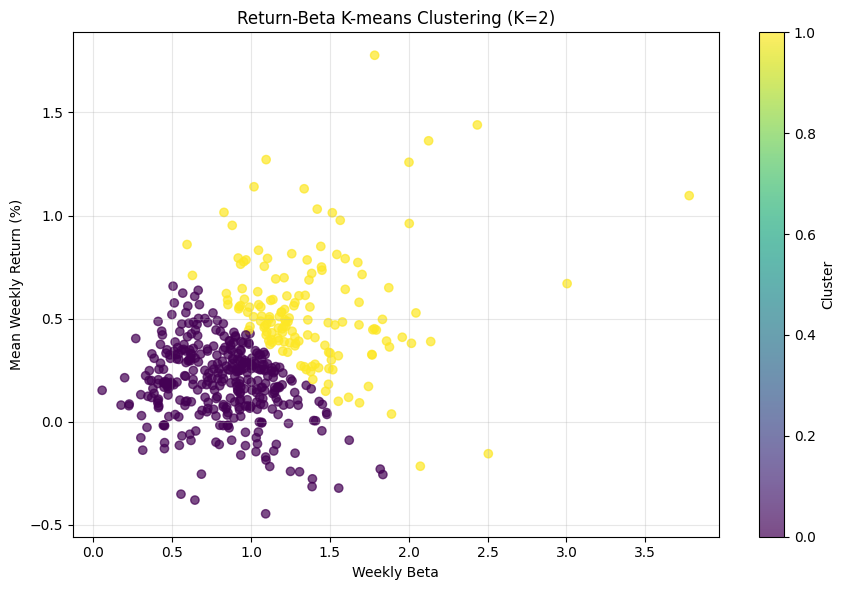

In [ ]:

# Visualise Return-Beta K-means clusters
plt.figure(figsize=(9, 6))

plt.scatter(
    final_features["Weekly Beta"],
    final_features["Mean Weekly Return"] * 100,
    c=final_features["Return-Beta KMeans Cluster"],
    cmap="viridis",
    alpha=0.7
)

plt.xlabel("Weekly Beta")
plt.ylabel("Mean Weekly Return (%)")
plt.title("Return-Beta K-means Clustering (K=2)")

plt.colorbar(label="Cluster")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


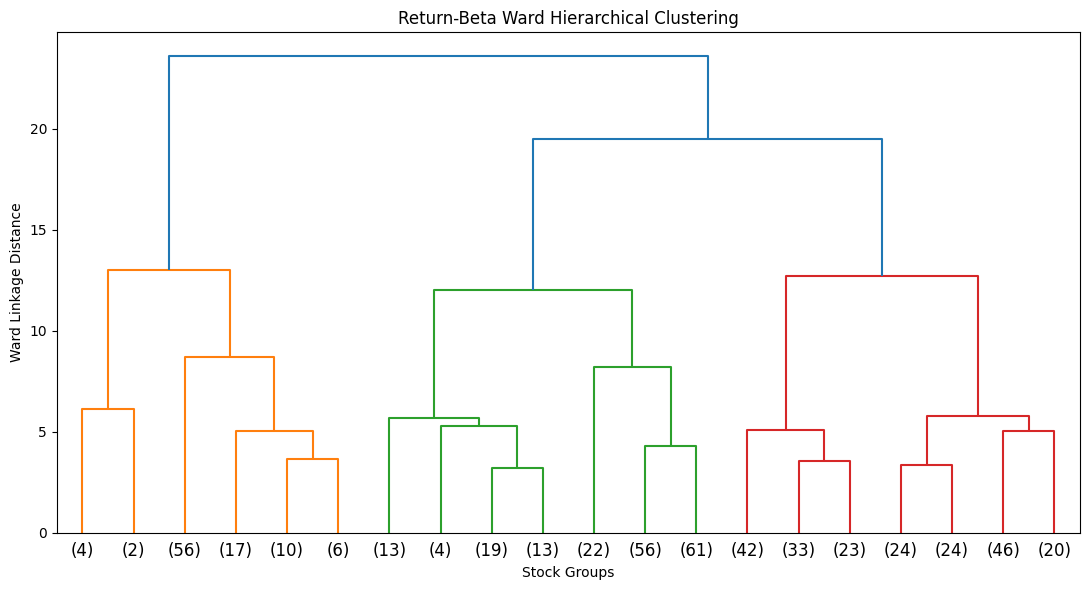

In [ ]:

# Import hierarchical clustering tools
from scipy.cluster.hierarchy import linkage, dendrogram

# Apply Ward hierarchical clustering
return_beta_linkage = linkage(
    return_beta_scaled,
    method="ward",
    metric="euclidean"
)

# Plot the dendrogram
plt.figure(figsize=(11, 6))

dendrogram(
    return_beta_linkage,
    truncate_mode="lastp",
    p=20,
    show_leaf_counts=True
)

plt.title("Return-Beta Ward Hierarchical Clustering")
plt.xlabel("Stock Groups")
plt.ylabel("Ward Linkage Distance")

plt.tight_layout()
plt.show()


In [ ]:

# Evaluate Ward hierarchical clustering
from sklearn.cluster import AgglomerativeClustering

ward_results = []

for k in range(2, 9):

    model = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward",
        metric="euclidean"
    )

    labels = model.fit_predict(return_beta_scaled)

    score = silhouette_score(
        return_beta_scaled,
        labels
    )

    cluster_sizes = pd.Series(labels).value_counts()

    ward_results.append({
        "Clusters": k,
        "Silhouette Score": score,
        "Smallest Cluster": cluster_sizes.min(),
        "Largest Cluster": cluster_sizes.max()
    })

ward_scores = pd.DataFrame(ward_results)

print("Return-Beta Ward clustering results:")
print(ward_scores.round(4))


Return-Beta Ward clustering results:
   Clusters  Silhouette Score  Smallest Cluster  Largest Cluster
0         2            0.3501                95              400
1         3            0.2844                95              212
2         4            0.2911                 6              212
3         5            0.2723                 6              188
4         6            0.3006                 6              139
5         7            0.2960                 6              139
6         8            0.3130                 6              117


In [ ]:

# Apply Ward clustering with 2 clusters
return_beta_ward = AgglomerativeClustering(
    n_clusters=2,
    linkage="ward",
    metric="euclidean"
)

# Assign Ward cluster labels
ward_labels = return_beta_ward.fit_predict(
    return_beta_scaled
)

# Store the cluster labels
final_features["Return-Beta Ward Cluster"] = ward_labels

# Calculate Ward cluster profiles
ward_profiles = final_features.groupby(
    "Return-Beta Ward Cluster"
).agg(
    Stock_Count=("Symbol", "count"),
    Average_Weekly_Return=("Mean Weekly Return", "mean"),
    Average_Beta=("Weekly Beta", "mean")
)

# Convert weekly returns to percentages
ward_profiles["Average_Weekly_Return"] *= 100

print("Return-Beta Ward Cluster Profiles:")
print(ward_profiles.round(4))


Return-Beta Ward Cluster Profiles:
                          Stock_Count  Average_Weekly_Return  Average_Beta
Return-Beta Ward Cluster                                                  
0                                 400                 0.2082        0.9006
1                                  95                 0.6477        1.3259


In [ ]:

# Compare K-means and Ward cluster assignments
from sklearn.metrics import adjusted_rand_score

ari_score = adjusted_rand_score(
    final_features["Return-Beta KMeans Cluster"],
    final_features["Return-Beta Ward Cluster"]
)

print("Return-Beta K-means vs Ward ARI:")
print(round(ari_score, 4))

# Compare the stock assignments
comparison_table = pd.crosstab(
    final_features["Return-Beta KMeans Cluster"],
    final_features["Return-Beta Ward Cluster"]
)

print("\nCluster assignment comparison:")
print(comparison_table)


Return-Beta K-means vs Ward ARI:
0.6047

Cluster assignment comparison:
Return-Beta Ward Cluster      0   1
Return-Beta KMeans Cluster         
0                           349   0
1                            51  95


In [ ]:

# Evaluate RFM K-means clustering
rfm_kmeans_results = []

for k in range(2, 9):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(rfm_scaled)

    score = silhouette_score(rfm_scaled, labels)

    sizes = pd.Series(labels).value_counts()

    rfm_kmeans_results.append({
        "Clusters": k,
        "Silhouette Score": score,
        "Inertia": model.inertia_,
        "Smallest Cluster": sizes.min(),
        "Largest Cluster": sizes.max()
    })

rfm_kmeans_scores = pd.DataFrame(rfm_kmeans_results)

print("RFM K-means evaluation:")
print(rfm_kmeans_scores.round(4))


RFM K-means evaluation:
   Clusters  Silhouette Score    Inertia  Smallest Cluster  Largest Cluster
0         2            0.4186  1087.2295                72              423
1         3            0.3272   813.7798                65              279
2         4            0.3416   620.9367                62              215
3         5            0.3579   524.8057                11              201
4         6            0.3461   445.0331                11              144
5         7            0.3482   395.6638                 1              143
6         8            0.3472   350.4695                 1              141


In [ ]:

# Apply RFM K-means with 2 clusters
rfm_kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

# Assign cluster labels
rfm_labels = rfm_kmeans.fit_predict(rfm_scaled)

# Save labels in the main dataset
final_features["RFM KMeans Cluster"] = rfm_labels

# Calculate cluster profiles using original RFM values
rfm_profiles = final_features.groupby(
    "RFM KMeans Cluster"
).agg(
    Stock_Count=("Symbol", "count"),
    Average_Recency=("Recency", "mean"),
    Average_Frequency=("Frequency", "mean"),
    Average_Monetary=("Monetary", "mean")
)

# Show Monetary in billions of USD
rfm_profiles["Average_Monetary"] /= 1e9

print("RFM K-means Cluster Profiles:")
print(rfm_profiles.round(2))


RFM K-means Cluster Profiles:
                    Stock_Count  Average_Recency  Average_Frequency  \
RFM KMeans Cluster                                                    
0                           423            13.39               3.20   
1                            72            62.49               1.85   

                    Average_Monetary  
RFM KMeans Cluster                    
0                              32.66  
1                              80.60  


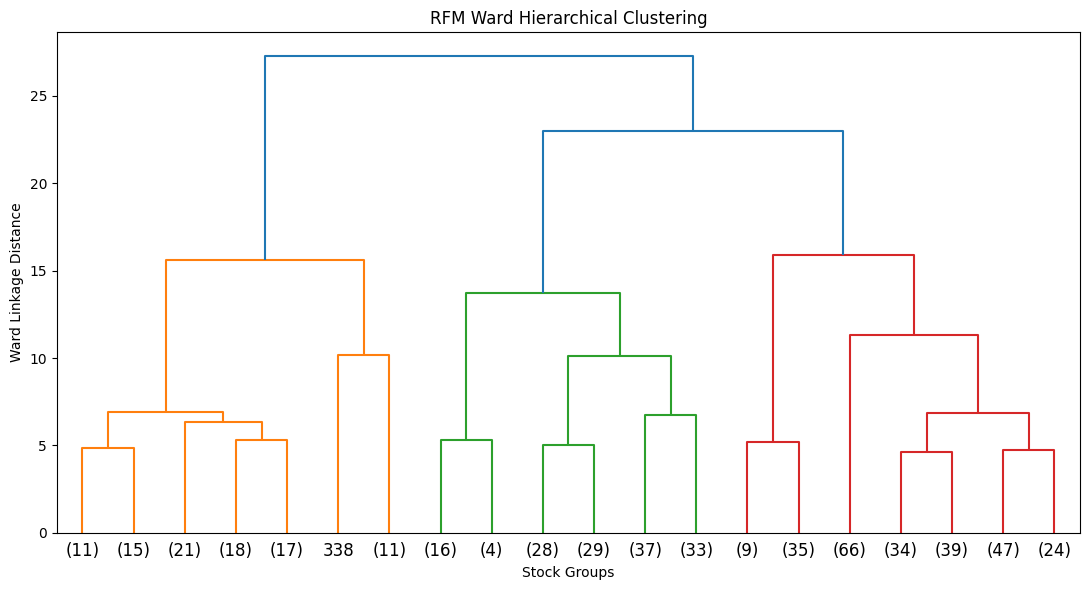

In [ ]:

# Apply Ward hierarchical clustering to RFM
rfm_linkage = linkage(
    rfm_scaled,
    method="ward",
    metric="euclidean"
)

# Display the dendrogram
plt.figure(figsize=(11, 6))

dendrogram(
    rfm_linkage,
    truncate_mode="lastp",
    p=20,
    show_leaf_counts=True
)

plt.title("RFM Ward Hierarchical Clustering")
plt.xlabel("Stock Groups")
plt.ylabel("Ward Linkage Distance")

plt.tight_layout()
plt.show()


In [ ]:

# Evaluate RFM Ward clustering
rfm_ward_results = []

for k in range(2, 9):

    model = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward",
        metric="euclidean"
    )

    labels = model.fit_predict(rfm_scaled)

    score = silhouette_score(rfm_scaled, labels)

    cluster_sizes = pd.Series(labels).value_counts()

    rfm_ward_results.append({
        "Clusters": k,
        "Silhouette Score": score,
        "Smallest Cluster": cluster_sizes.min(),
        "Largest Cluster": cluster_sizes.max()
    })

rfm_ward_scores = pd.DataFrame(rfm_ward_results)

print("RFM Ward clustering evaluation:")
print(rfm_ward_scores.round(4))


RFM Ward clustering evaluation:
   Clusters  Silhouette Score  Smallest Cluster  Largest Cluster
0         2            0.3584                94              401
1         3            0.3080                94              254
2         4            0.2923                44              210
3         5            0.3115                12              210
4         6            0.3201                12              210
5         7            0.2991                12              144
6         8            0.3009                 1              144


In [ ]:

# Apply RFM Ward clustering with 2 clusters
rfm_ward = AgglomerativeClustering(
    n_clusters=2,
    linkage="ward",
    metric="euclidean"
)

# Assign cluster labels
rfm_ward_labels = rfm_ward.fit_predict(rfm_scaled)

# Store labels in the main dataset
final_features["RFM Ward Cluster"] = rfm_ward_labels

# Calculate profiles using original RFM values
rfm_ward_profiles = final_features.groupby(
    "RFM Ward Cluster"
).agg(
    Stock_Count=("Symbol", "count"),
    Average_Recency=("Recency", "mean"),
    Average_Frequency=("Frequency", "mean"),
    Average_Monetary=("Monetary", "mean")
)

# Convert Monetary to billions of USD
rfm_ward_profiles["Average_Monetary"] /= 1e9

print("RFM Ward Cluster Profiles:")
print(rfm_ward_profiles.round(2))


RFM Ward Cluster Profiles:
                  Stock_Count  Average_Recency  Average_Frequency  \
RFM Ward Cluster                                                    
0                         401            12.32               3.22   
1                          94            55.53               2.07   

                  Average_Monetary  
RFM Ward Cluster                    
0                            38.22  
1                            45.65  


In [ ]:

# Compare RFM K-means and Ward cluster assignments
rfm_ari = adjusted_rand_score(
    final_features["RFM KMeans Cluster"],
    final_features["RFM Ward Cluster"]
)

print("RFM K-means vs Ward ARI:")
print(round(rfm_ari, 4))

# Show how stocks are assigned by both methods
rfm_comparison = pd.crosstab(
    final_features["RFM KMeans Cluster"],
    final_features["RFM Ward Cluster"]
)

print("\nRFM Cluster Assignment Comparison:")
print(rfm_comparison)


RFM K-means vs Ward ARI:
0.753

RFM Cluster Assignment Comparison:
RFM Ward Cluster      0   1
RFM KMeans Cluster         
0                   399  24
1                     2  70


RFM Feature Correlation Matrix:
              Recency  Frequency  Log Monetary
Recency        1.0000    -0.3413        0.1639
Frequency     -0.3413     1.0000        0.0188
Log Monetary   0.1639     0.0188        1.0000


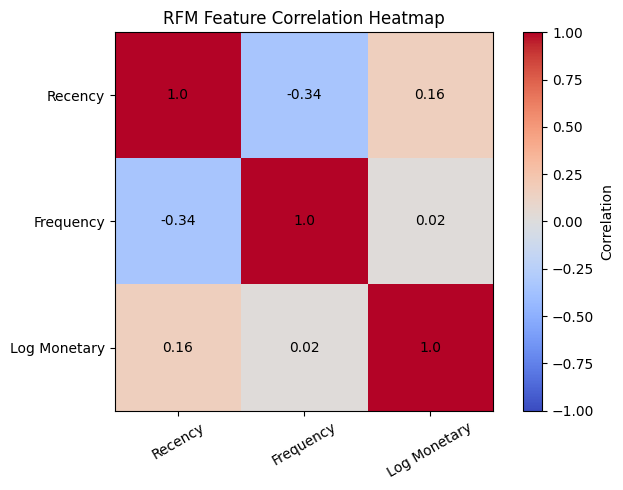

In [ ]:

# Calculate correlations between RFM features
rfm_correlation = final_features[
    ["Recency", "Frequency", "Log Monetary"]
].corr()

print("RFM Feature Correlation Matrix:")
print(rfm_correlation.round(4))

# Display a correlation heatmap
plt.figure(figsize=(7, 5))

plt.imshow(
    rfm_correlation,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.colorbar(label="Correlation")

plt.xticks(
    range(3),
    rfm_correlation.columns,
    rotation=30
)

plt.yticks(
    range(3),
    rfm_correlation.columns
)

# Add correlation values inside the heatmap
for i in range(3):
    for j in range(3):
        plt.text(
            j, i,
            round(rfm_correlation.iloc[i, j], 2),
            ha="center",
            va="center"
        )

plt.title("RFM Feature Correlation Heatmap")
plt.tight_layout()
plt.show()


In [ ]:

# Select RFM features without Monetary
rf_features = final_features[
    ["Recency", "Frequency"]
].copy()

# Standardise the two remaining features
rf_scaler = StandardScaler()
rf_scaled = rf_scaler.fit_transform(rf_features)

# Apply Ward clustering with the same K = 2
rf_ward = AgglomerativeClustering(
    n_clusters=2,
    linkage="ward",
    metric="euclidean"
)

rf_ward_labels = rf_ward.fit_predict(rf_scaled)

# Save the new cluster labels
final_features["RF Ward Cluster"] = rf_ward_labels

# Compare original RFM Ward with RF Ward
rf_sensitivity_ari = adjusted_rand_score(
    final_features["RFM Ward Cluster"],
    final_features["RF Ward Cluster"]
)

print("RFM Ward vs RF Ward ARI:")
print(round(rf_sensitivity_ari, 4))

print("\nRF Ward Cluster Sizes:")
print(
    final_features["RF Ward Cluster"].value_counts().sort_index()
)

print("\nCluster Assignment Comparison:")
print(
    pd.crosstab(
        final_features["RFM Ward Cluster"],
        final_features["RF Ward Cluster"]
    )
)


RFM Ward vs RF Ward ARI:
0.9529

RF Ward Cluster Sizes:
RF Ward Cluster
0    402
1     93
Name: count, dtype: int64

Cluster Assignment Comparison:
RF Ward Cluster     0   1
RFM Ward Cluster         
0                 399   2
1                   3  91


In [ ]:

# Calculate RF Ward cluster profiles
rf_ward_profiles = final_features.groupby(
    "RF Ward Cluster"
).agg(
    Stock_Count=("Symbol", "count"),
    Average_Recency=("Recency", "mean"),
    Average_Frequency=("Frequency", "mean"),
    Average_Monetary=("Monetary", "mean"),
    Median_Monetary=("Monetary", "median")
)

# Convert Monetary values to billions of USD
rf_ward_profiles["Average_Monetary"] /= 1e9
rf_ward_profiles["Median_Monetary"] /= 1e9

print("RF Ward Cluster Profiles:")
print(rf_ward_profiles.round(2))


RF Ward Cluster Profiles:
                 Stock_Count  Average_Recency  Average_Frequency  \
RF Ward Cluster                                                    
0                        402            12.31               3.22   
1                         93            56.03               2.05   

                 Average_Monetary  Median_Monetary  
RF Ward Cluster                                     
0                            37.7            15.40  
1                            48.0            21.05  


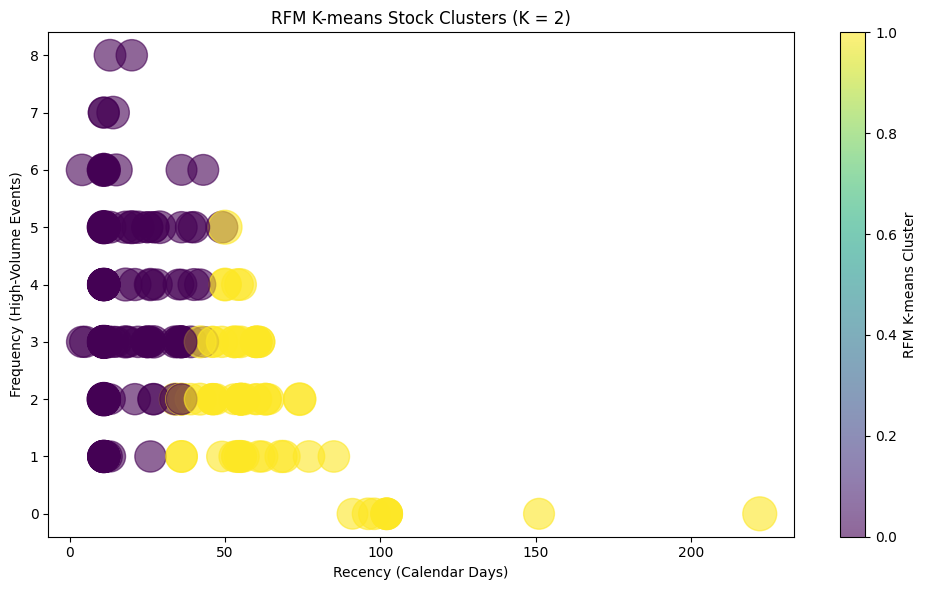

In [ ]:

# Visualise RFM K-means clusters
plt.figure(figsize=(10, 6))

plt.scatter(
    final_features["Recency"],
    final_features["Frequency"],
    c=final_features["RFM KMeans Cluster"],
    s=30 + 20 * final_features["Log Monetary"],
    cmap="viridis",
    alpha=0.6
)

plt.xlabel("Recency (Calendar Days)")
plt.ylabel("Frequency (High-Volume Events)")
plt.title("RFM K-means Stock Clusters (K = 2)")

plt.colorbar(label="RFM K-means Cluster")

plt.tight_layout()
plt.show()


In [ ]:

# Check available sector information
print("Company table columns:")
print(companies.columns.tolist())

print("\nFirst five company records:")
print(companies.head())


Company table columns:
['Symbol', 'Security', 'GICS Sector', 'GICS Sub-Industry', 'Headquarters Location', 'Date added', 'CIK', 'Founded']

First five company records:
  Symbol             Security             GICS Sector  \
0    MMM                   3M             Industrials   
1    AOS          A. O. Smith             Industrials   
2    ABT  Abbott Laboratories             Health Care   
3   ABBV               AbbVie             Health Care   
4    ACN            Accenture  Information Technology   

                GICS Sub-Industry    Headquarters Location  Date added  \
0        Industrial Conglomerates    Saint Paul, Minnesota  1957-03-04   
1               Building Products     Milwaukee, Wisconsin  2017-07-26   
2           Health Care Equipment  North Chicago, Illinois  1957-03-04   
3                   Biotechnology  North Chicago, Illinois  2012-12-31   
4  IT Consulting & Other Services          Dublin, Ireland  2011-07-06   

       CIK      Founded  
0    66740        

In [ ]:

# Select company information needed for the analysis
sector_data = companies[
    ["Symbol", "Security", "GICS Sector"]
].copy()

# Match ticker formatting used in Yahoo Finance
sector_data["Symbol"] = sector_data["Symbol"].str.replace(
    ".", "-", regex=False
)

# Merge sector information with stock features
final_features = final_features.merge(
    sector_data,
    on="Symbol",
    how="left",
    validate="one_to_one"
)

# Check the results
print("Total stocks:", len(final_features))

print("Stocks without sector information:")
print(final_features["GICS Sector"].isna().sum())

print("\nFirst five records:")
print(
    final_features[
        ["Symbol", "Security", "GICS Sector", "RFM KMeans Cluster"]
    ].head()
)


Total stocks: 495
Stocks without sector information:
0

First five records:
  Symbol             Security             GICS Sector  RFM KMeans Cluster
0    MMM                   3M             Industrials                   0
1    AOS          A. O. Smith             Industrials                   0
2    ABT  Abbott Laboratories             Health Care                   0
3   ABBV               AbbVie             Health Care                   0
4    ACN            Accenture  Information Technology                   0


In [ ]:

# Count stocks in each sector and RFM cluster
sector_counts = pd.crosstab(
    final_features["GICS Sector"],
    final_features["RFM KMeans Cluster"]
)

print("Sector Counts by RFM K-means Cluster:")
print(sector_counts)

# Calculate percentages within each cluster
sector_percentages = sector_counts.div(
    sector_counts.sum(axis=0),
    axis=1
) * 100

print("\nSector Percentages Within Each Cluster:")
print(sector_percentages.round(2))


Sector Counts by RFM K-means Cluster:
RFM KMeans Cluster       0   1
GICS Sector                   
Communication Services  19   2
Consumer Discretionary  39   8
Consumer Staples        27   5
Energy                  20   1
Financials              64  12
Health Care             51   8
Industrials             75   5
Information Technology  59  15
Materials               18   6
Real Estate             30   0
Utilities               21  10

Sector Percentages Within Each Cluster:
RFM KMeans Cluster          0      1
GICS Sector                         
Communication Services   4.49   2.78
Consumer Discretionary   9.22  11.11
Consumer Staples         6.38   6.94
Energy                   4.73   1.39
Financials              15.13  16.67
Health Care             12.06  11.11
Industrials             17.73   6.94
Information Technology  13.95  20.83
Materials                4.26   8.33
Real Estate              7.09   0.00
Utilities                4.96  13.89


In [ ]:

# Calculate each sector's percentage in the full dataset
overall_sector_percent = (
    final_features["GICS Sector"]
    .value_counts(normalize=True) * 100
)

# Compare cluster percentages with overall percentages
sector_comparison = sector_percentages.copy()

sector_comparison["Overall %"] = overall_sector_percent

sector_comparison["Cluster 0 Difference"] = (
    sector_comparison[0] - sector_comparison["Overall %"]
)

sector_comparison["Cluster 1 Difference"] = (
    sector_comparison[1] - sector_comparison["Overall %"]
)

print("Sector Representation Compared with Overall Dataset:")
print(sector_comparison.round(2))


Sector Representation Compared with Overall Dataset:
RFM KMeans Cluster          0      1  Overall %  Cluster 0 Difference  \
GICS Sector                                                             
Communication Services   4.49   2.78       4.24                  0.25   
Consumer Discretionary   9.22  11.11       9.49                 -0.28   
Consumer Staples         6.38   6.94       6.46                 -0.08   
Energy                   4.73   1.39       4.24                  0.49   
Financials              15.13  16.67      15.35                 -0.22   
Health Care             12.06  11.11      11.92                  0.14   
Industrials             17.73   6.94      16.16                  1.57   
Information Technology  13.95  20.83      14.95                 -1.00   
Materials                4.26   8.33       4.85                 -0.59   
Real Estate              7.09   0.00       6.06                  1.03   
Utilities                4.96  13.89       6.26                 -1.30  

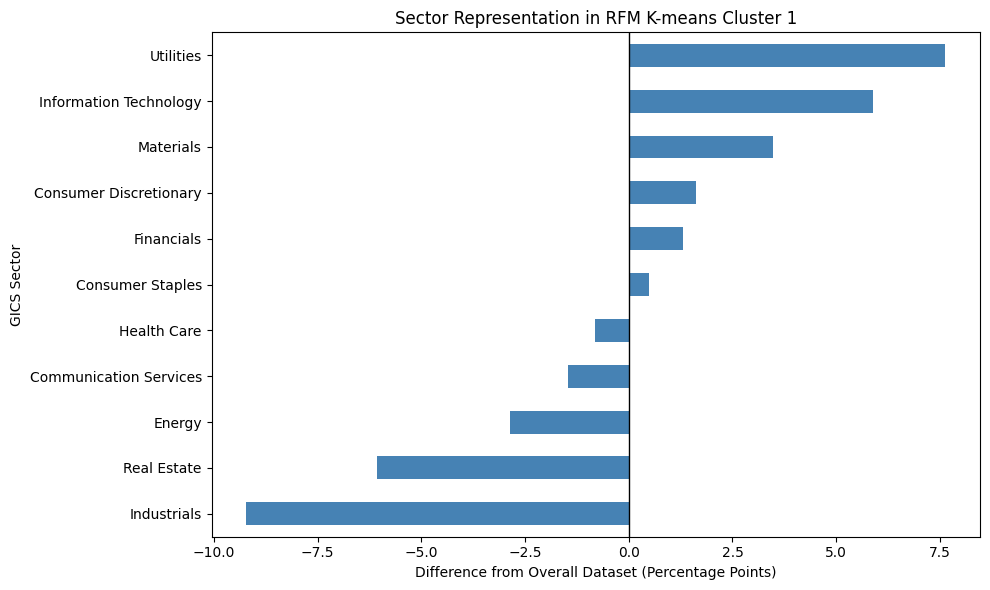

In [ ]:

# Sort sectors by their representation difference
sector_difference = sector_comparison[
    "Cluster 1 Difference"
].sort_values()

# Create a horizontal bar chart
plt.figure(figsize=(10, 6))

sector_difference.plot(
    kind="barh",
    color="steelblue"
)

# Add a reference line at zero
plt.axvline(0, color="black", linewidth=1)

plt.xlabel("Difference from Overall Dataset (Percentage Points)")
plt.ylabel("GICS Sector")
plt.title("Sector Representation in RFM K-means Cluster 1")

plt.tight_layout()
plt.show()


In [ ]:

# Check the final stock dataset
required_columns = [
    "Symbol",
    "GICS Sector",
    "Mean Weekly Return",
    "Weekly Beta",
    "Weeks Used",
    "Recency",
    "Frequency",
    "Monetary",
    "Log Monetary",
    "Return-Beta KMeans Cluster",
    "Return-Beta Ward Cluster",
    "RFM KMeans Cluster",
    "RFM Ward Cluster",
    "RF Ward Cluster"
]

print("Total stocks:", len(final_features))

print("Duplicate stock symbols:")
print(final_features["Symbol"].duplicated().sum())

print("\nMissing values in required columns:")
print(final_features[required_columns].isna().sum())

print("\nCluster counts:")
for column in required_columns[-5:]:
    print("\n", column)
    print(final_features[column].value_counts().sort_index())


Total stocks: 495
Duplicate stock symbols:
0

Missing values in required columns:
Symbol                        0
GICS Sector                   0
Mean Weekly Return            0
Weekly Beta                   0
Weeks Used                    0
Recency                       0
Frequency                     0
Monetary                      0
Log Monetary                  0
Return-Beta KMeans Cluster    0
Return-Beta Ward Cluster      0
RFM KMeans Cluster            0
RFM Ward Cluster              0
RF Ward Cluster               0
dtype: int64

Cluster counts:

 Return-Beta KMeans Cluster
Return-Beta KMeans Cluster
0    349
1    146
Name: count, dtype: int64

 Return-Beta Ward Cluster
Return-Beta Ward Cluster
0    400
1     95
Name: count, dtype: int64

 RFM KMeans Cluster
RFM KMeans Cluster
0    423
1     72
Name: count, dtype: int64

 RFM Ward Cluster
RFM Ward Cluster
0    401
1     94
Name: count, dtype: int64

 RF Ward Cluster
RF Ward Cluster
0    402
1     93
Name: count, dtype: int64


In [ ]:

# Investigate historical volume records for SW
sw_data = stock_data["SW"].copy()

print("Total trading records:", len(sw_data))
print("Zero-volume records:", (sw_data["Volume"] == 0).sum())

print("\nFirst 5 records:")
print(sw_data[["Close", "Volume"]].head())

print("\nLast 5 zero-volume records:")
print(
    sw_data.loc[
        sw_data["Volume"] == 0,
        ["Close", "Volume"]
    ].tail()
)

print("\nSW RFM values:")
print(
    final_features.loc[
        final_features["Symbol"] == "SW",
        ["Symbol", "Recency", "Frequency", "Monetary"]
    ]
)


Total trading records: 1005
Zero-volume records: 424

First 5 records:
Price           Close  Volume
Date                         
2021-01-04  47.610001     500
2021-01-05  47.610001       0
2021-01-06  47.610001       0
2021-01-07  47.610001     500
2021-01-08  49.209999   12500

Last 5 zero-volume records:
Price           Close  Volume
Date                         
2024-06-13  47.040001       0
2024-06-17  44.799999       0
2024-06-25  46.090000       0
2024-07-02  46.099998       0
2024-07-05  45.160000       0

SW RFM values:
    Symbol  Recency  Frequency      Monetary
407     SW       11          3  1.112658e+10


In [ ]:

# Check SW's high-volume events
sw_data = stock_data["SW"].copy()

# Calculate the average volume of the previous 20 sessions
sw_data["Previous_20_Avg"] = (
    sw_data["Volume"]
    .shift(1)
    .rolling(window=20, min_periods=20)
    .mean()
)

# Identify qualifying high-volume events
sw_data["High_Volume_Event"] = (
    sw_data["Volume"] > 2 * sw_data["Previous_20_Avg"]
)

# Show events in the final 60 trading sessions
sw_recent = sw_data.tail(60)

print("SW high-volume events in final 60 sessions:")
print(
    sw_recent.loc[
        sw_recent["High_Volume_Event"],
        ["Volume", "Previous_20_Avg"]
    ]
)

# Check for zero volumes in event baseline windows
print("\nZero-volume days in final 80 sessions:")
print((sw_data.tail(80)["Volume"] == 0).sum())


SW high-volume events in final 60 sessions:
Price         Volume  Previous_20_Avg
Date                                 
2024-10-30   7886300        3353985.0
2024-11-20   7857300        3835195.0
2024-12-20  10253500        3321355.0

Zero-volume days in final 80 sessions:
0


In [ ]:

# Check which downloaded stocks are excluded
all_stocks = set(stock_features["Symbol"])
included_stocks = set(final_features["Symbol"])

excluded_stocks = sorted(all_stocks - included_stocks)

print("Stocks with calculated Return-Beta features:", len(all_stocks))
print("Stocks included in final analysis:", len(included_stocks))
print("Excluded after feature calculation:", len(excluded_stocks))

print("\nExcluded stocks and weekly observation counts:")
print(
    stock_features[
        stock_features["Symbol"].isin(excluded_stocks)
    ][["Symbol", "Weeks Used"]]
)


Stocks with calculated Return-Beta features: 498
Stocks included in final analysis: 495
Excluded after feature calculation: 3

Excluded stocks and weekly observation counts:
    Symbol  Weeks Used
210    GEV          39
382   RDDT          40
411   SOLV          39


In [ ]:

# Create an exclusion log
exclusion_records = []

# Symbols with no downloaded data
failed_symbols = ["FDXF", "HONA", "Q", "SNDK", "VYLR"]

for symbol in failed_symbols:
    exclusion_records.append({
        "Symbol": symbol,
        "Reason": "No usable price data downloaded"
    })

# Symbols with insufficient weekly observations
for symbol in excluded_stocks:
    weeks = stock_features.loc[
        stock_features["Symbol"] == symbol,
        "Weeks Used"
    ].iloc[0]

    exclusion_records.append({
        "Symbol": symbol,
        "Reason": f"Only {weeks} aligned weekly returns"
    })

# Convert to a DataFrame
exclusion_log = pd.DataFrame(exclusion_records)

print("Final Stock Exclusion Log:")
print(exclusion_log)

print("\nTotal excluded symbols:", len(exclusion_log))


Final Stock Exclusion Log:
  Symbol                           Reason
0   FDXF  No usable price data downloaded
1   HONA  No usable price data downloaded
2      Q  No usable price data downloaded
3   SNDK  No usable price data downloaded
4   VYLR  No usable price data downloaded
5    GEV   Only 39 aligned weekly returns
6   RDDT   Only 40 aligned weekly returns
7   SOLV   Only 39 aligned weekly returns

Total excluded symbols: 8


In [ ]:

# Save the final stock feature dataset
final_features.to_csv(
    "sp500_final_features.csv",
    index=False
)

# Save the stock exclusion log
exclusion_log.to_csv(
    "sp500_exclusion_log.csv",
    index=False
)

# Check the saved files
import os

files_to_check = [
    "sp500_final_features.csv",
    "sp500_exclusion_log.csv"
]

for filename in files_to_check:
    print(filename, "- Saved:", os.path.exists(filename))

print("\nFinal dataset shape:", final_features.shape)
print("Exclusion log shape:", exclusion_log.shape)


sp500_final_features.csv - Saved: True
sp500_exclusion_log.csv - Saved: True

Final dataset shape: (495, 16)
Exclusion log shape: (8, 2)


In [ ]:

# Download the CSV files from Google Colab
from google.colab import files

files.download("sp500_final_features.csv")
files.download("sp500_exclusion_log.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# Check whether the raw stock data file exists
import os

filename = "sp500_raw_data.pkl"

print("Raw data file exists:", os.path.exists(filename))

if os.path.exists(filename):
    print("File size (MB):", round(os.path.getsize(filename) / (1024 * 1024), 2))


Raw data file exists: True
File size (MB): 23.47


In [ ]:

# Download the raw stock data file
from google.colab import files

files.download("sp500_raw_data.pkl")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# Save the S&P 500 company list
companies.to_csv("sp500_companies.csv", index=False)

# Download the company list
from google.colab import files
files.download("sp500_companies.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# Check the Python and library versions
import sys
import pandas
import numpy
import yfinance
import sklearn
import scipy
import matplotlib

print("Python:", sys.version.split()[0])
print("Pandas:", pandas.__version__)
print("NumPy:", numpy.__version__)
print("yfinance:", yfinance.__version__)
print("Scikit-learn:", sklearn.__version__)
print("SciPy:", scipy.__version__)
print("Matplotlib:", matplotlib.__version__)


Python: 3.13.18
Pandas: 2.2.3
NumPy: 2.4.6
yfinance: 0.2.66
Scikit-learn: 1.6.1
SciPy: 1.16.3
Matplotlib: 3.10.0


In [ ]:

# Create a requirements file
requirements = """pandas==2.2.3
numpy==2.4.6
yfinance==0.2.66
scikit-learn==1.6.1
scipy==1.16.3
matplotlib==3.10.0
requests
lxml
html5lib
"""

with open("requirements.txt", "w") as file:
    file.write(requirements)

print("requirements.txt created successfully")

# Display the contents
with open("requirements.txt", "r") as file:
    print(file.read())


requirements.txt created successfully
pandas==2.2.3
numpy==2.4.6
yfinance==0.2.66
scikit-learn==1.6.1
scipy==1.16.3
matplotlib==3.10.0
requests
lxml
html5lib



In [ ]:

# Download the requirements file
from google.colab import files

files.download("requirements.txt")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:

# Create the README file for the GitHub repository

readme = """# S&P 500 Stock Analysis Using RFM and Clustering

## About This Project

In this project, I analysed S&P 500 stocks using
historical stock market data from 2021 to 2024.

My aim was to group stocks based on their weekly
returns, market risk and trading activity.

I used two sets of features:
- Average weekly return and weekly beta
- Recency, Frequency and Monetary (RFM)

I used K-means and Ward hierarchical clustering
to compare how the stocks were grouped.

## Data Sources

I collected the S&P 500 company list from Wikipedia
on 12 November 2026.

Source:
https://en.wikipedia.org/wiki/List_of_S%26P_500_companies

I downloaded daily stock prices and trading volumes
from Yahoo Finance using the yfinance library.

The study period was from 1 January 2021 to
31 December 2024.

I used the S&P 500 index (^GSPC) as the benchmark.

## Data Preparation

I started with 503 stock symbols.

Five symbols did not return usable data:
FDXF, HONA, Q, SNDK and VYLR.

I removed another three stocks because they had
fewer than 52 aligned weekly returns:
GEV, RDDT and SOLV.

This left 495 stocks for the final analysis.

I checked the data for duplicate dates, missing
values, invalid prices and unusual trading volumes.

I used adjusted closing prices to calculate
weekly returns and beta.

## Feature Calculations

### Average Weekly Return

I used Friday-ending weekly adjusted closing prices
to calculate weekly returns.

I then calculated the average weekly return
for each stock.

### Weekly Beta

I calculated weekly beta by comparing each stock's
weekly returns with the S&P 500 index.

### Recency

Recency is the number of calendar days since the
most recent high-volume trading event.

I identified a high-volume event when the daily
volume was more than twice the average volume
of the previous 20 trading sessions.

### Frequency

Frequency is the number of high-volume events
during the final 60 trading sessions.

### Monetary

Monetary is the total estimated trading value
during the final 60 trading sessions.

I calculated this using the closing price
multiplied by the daily trading volume.

This value does not represent company profit
or market capitalisation.

The RFM observation date was 31 December 2024.

## Clustering Methods

I used two separate feature sets:
- Average weekly return and weekly beta
- Recency, Frequency and Monetary

I applied a log transformation to Monetary
because its values were highly skewed.

I standardised the features before clustering.

I used K-means and Ward hierarchical clustering.

I tested cluster numbers from 2 to 8.

I compared silhouette scores, cluster sizes
and average feature values.

I selected two clusters for the main comparisons.

## Main Results

### Return and Beta Clustering

K-means divided the 495 stocks into two groups.

Cluster 0 contained 349 stocks.
Cluster 1 contained 146 stocks.

Cluster 0 had lower average weekly returns
and lower beta values than Cluster 1.

### RFM Clustering

K-means divided the stocks into two groups.

Cluster 0 contained 423 stocks.
Cluster 1 contained 72 stocks.

Cluster 0 had more recent high-volume events
and a higher average event frequency.

Cluster 1 had less recent high-volume events
and a lower average event frequency.

### Comparing the Methods

I compared K-means and Ward clustering
using the adjusted Rand index.

I also tested Ward clustering without Monetary
to see whether the RFM groups changed.

Most stock assignments stayed the same.

I also compared the sectors represented
in the RFM clusters.

## Limitations

I used the S&P 500 company list from November 2026
to study the period from 2021 to 2024.

This creates survivorship bias because the list
does not show the exact companies in the index
during each historical year.

Some stocks had shorter trading histories.

Some historical trading volumes were unusual.
For example, SW had 424 zero-volume records.

Monetary is only an estimate of trading value.

The clusters describe past market behaviour.
They do not predict future stock performance.

## Project Files

- CW1-CRnCM-SP500_RFM_Analysis.ipynb
  Contains the Python analysis and charts.

- sp500_companies.csv
  Contains the S&P 500 company list.

- sp500_raw_data.pkl
  Contains the downloaded historical stock data.

- sp500_final_features.csv
  Contains the final features and cluster results.

- sp500_exclusion_log.csv
  Contains the excluded stocks and reasons.

- requirements.txt
  Lists the Python libraries used.

## How to Run the Project

1. Open the notebook in Google Colab.
2. Install the libraries listed in requirements.txt.
3. Run the notebook cells in order.
4. Review the calculated features and clustering results.

The notebook downloads historical stock data from Yahoo Finance
using yfinance. A new download may return different results
or unavailable symbols.

The file sp500_raw_data.pkl contains the original downloaded
data used for this analysis. It is included as a historical
snapshot to support reproducibility.

The original S&P 500 company list was collected from Wikipedia
on 12 November 2026.

A fresh-run test was completed on 22 November 2026 using
a separate Google Colab environment. The test successfully
executed the analysis and reproduced the main clustering results.

Only load pickle files from trusted sources.

## Software Used

- Python 3.13.18
- Pandas 2.2.3
- NumPy 2.4.6
- yfinance 0.2.66
- Scikit-learn 1.6.1
- SciPy 1.16.3
- Matplotlib 3.10.0
"""

# Save README.md
with open("README.md", "w", encoding="utf-8") as file:
    file.write(readme)

print("README.md created successfully!")


README.md created successfully!


In [2]:

from google.colab import files

files.download("README.md")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>